# **Lake Mendota Zooplankton and Water Clarity**
### Lake Mendota is the most studied lake in the world. In 2009, it experienced an outbreak in the population of spiny water fleas. Spiny water fleas eat daphnia, which are prolific algae eaters. This project quantifies changes in both zooplankton populations and water clarity before and after the outbreak.

## **Main Research Question**
## When did the spiny water flea arrive in Lake Mendota and did the water get murkier after 2009? 
### **Subquestions**
### 1. When does the spiny water flea first appear in the zooplankton counts, and how fast did it increase?
### 2. Did Daphnia numbers in Mendota drop after 2009?
### 3. How has Mendota's average summer clarity changed yearly since 1995?
### 4. Did clarity become more variable from year to year after 2009, and not just lower on average?

## Data and Methods

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm

### This project uses two CSV datasets containing long-term ecological data from Lake Mendota. These datasets were obtained from the Environmental Data Intitiative repository.
- nt131_v11.csv -- contains secchi depth measurements for Wisconsin lakes
- nt190_v12.csv -- contains counts and body lengths of zooplankton, including daphnia and the spiny water flea, for Wisconsin lakes

In [8]:
df1 = pd.read_csv("data/knb-lter-ntl.31.34/ntl31_v11.csv")
df2 = pd.read_csv("data/knb-lter-ntl.90.37/ntl90_v12.csv")

## When does the spiny water flea first appear in the zooplankton counts, and how fast did it increase?

In [9]:
df2_swf_ME = df2[(df2["species_name"] == "BYTHOTREPHES LONGIMANUS\xa0") & (df2["lakeid"] == "ME")]
df2_swf_ME_cleaned = df2_swf_ME.drop(['station', 'towdepth'], axis = 1).reset_index(drop=True).rename(columns={'year4':'year'})
swf_mean_density_by_year = df2_swf_ME_cleaned.groupby(df2_swf_ME_cleaned['year'])['density'].mean().round().astype(int)
swf_mean_density_by_year_before_2015 = swf_mean_density_by_year[swf_mean_density_by_year.index < 2015]
swf_mean_density_by_year_after_2015 = swf_mean_density_by_year[swf_mean_density_by_year.index >= 2015]

([], [])

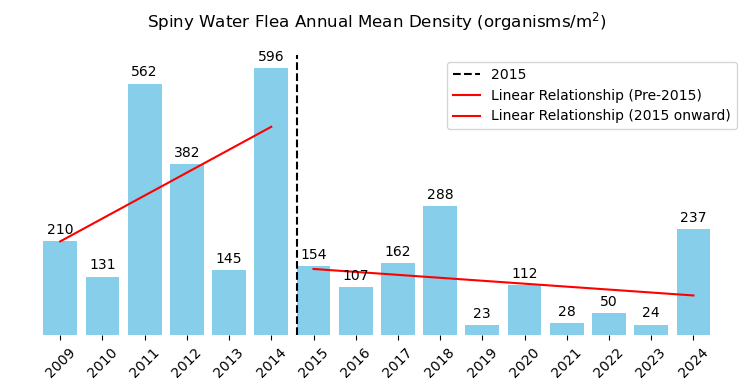

In [11]:
plt.figure(figsize=(8,4))
plt.title(r"Spiny Water Flea Annual Mean Density (organisms/m$^2$)", pad=20)
    
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
    
bars = plt.bar(swf_mean_density_by_year.index, swf_mean_density_by_year.values, color='skyblue')
ax.axvline(x=2014.6, color='black', linestyle='--', label='2015')
plt.bar_label(bars, padding=3)

ax.set_xticks(swf_mean_density_by_year.index)
ax.set_xticklabels(swf_mean_density_by_year.index.astype(str))
plt.xticks(rotation=45)
plt.tight_layout()

x1 = swf_mean_density_by_year_before_2015.index
y1 = swf_mean_density_by_year_before_2015.values
x2 = swf_mean_density_by_year_after_2015.index
y2 = swf_mean_density_by_year_after_2015.values

x1_with_intercept = sm.add_constant(x1)
pre_2015_model = sm.OLS(y1, x1_with_intercept)
results_pre = pre_2015_model.fit()
predictions_pre = results_pre.predict()

x2_with_intercept = sm.add_constant(x2)
post_2015_model = sm.OLS(y2, x2_with_intercept)
results_post = post_2015_model.fit()
predictions_post = results_post.predict()

ax.plot(x1, predictions_pre, color='red', label='Linear Relationship (Pre-2015)')
ax.plot(x2, predictions_post, color='red', label='Linear Relationship (2015 onward)')

ax.legend()

plt.yticks([])

In [12]:
print(results_post.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                 -0.073
Method:                 Least Squares   F-statistic:                    0.3885
Date:                Sat, 21 Nov 2026   Prob (F-statistic):              0.550
Time:                        16:41:30   Log-Likelihood:                -58.699
No. Observations:                  10   AIC:                             121.4
Df Residuals:                       8   BIC:                             122.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        1.34e+04   2.13e+04      0.629      0.5

C:\Users\xlila\anaconda3\lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


## Interpretation of Results
* The spiny water flea first appeared in Lake Mendota in 2009
* Beginning in 2009 and up until 2015, the average annual population density of the spiny water flea increased by an average of 51.2 organisms/m² per year, according to the results from the OLS regression model
* Beginning in 2015 and continuing through 2024, the average annual population density of the spiny water flea decreased by an average of ~6.58 organisms/m² per year

** Note that the dashed marker for year 2015 was moved slightly left to increase visibility of the year's annual mean density measurement. The first trendline includes years 2009-2014, and the second 2015-2024.

## Limitations of the Model
The inclusion of the linear trendlines serves purely to enhance visual comprehension of the graph, in terms of change in average annual population density. Only the coefficient for the independent variable (average annual population density) is useful. The relatively low number of observations used to fit the model reduces its statistical power, increases its sensitivity to noise, and inflates the p-value. The model was not used to draw any further conclusions for this reason. 

## Did Daphnia numbers in mendota drop after 2009?

In [26]:
df2_dph = df2[df2["species_name"].isin(["DAPHNIA MENDOTAE", "DAPHNIA PULICARIA", "DAPHNIA", "DAPHNIA RETROCURVA", "DAPHNIA PARVULA"])]
df2_dph_ME = df2_dph[df2_dph['lakeid'] == 'ME']
df2_dph_ME_cleaned = df2_dph_ME.drop(['station', 'towdepth'], axis = 1).reset_index(drop=True)
df2_dph_ME_cleaned['year_month'] = df2_dph_ME_cleaned['sample_date'].str.slice(0, 7)
dph_density_by_year_month = (df2_dph_ME_cleaned.groupby(['year_month', 'species_name'])['density'].mean().round().astype(int).reset_index()).sort_values(by='year_month')
target_years = ['1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014'
                , '2015','2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
dph_density_by_year_month_1995_on = dph_density_by_year_month[dph_density_by_year_month['year_month'].str.slice(0, 4).isin(target_years)].copy()

### Observation Counts by Daphnia Subspecies
* Daphnia Mendotae: 128 observations
* Daphnia Pulicaria: 109 observations
* Daphnia Retrocurva: 33 observations
* Daphnia Parvula: 42 observations

In [28]:
daphnia_mendotae_data = dph_density_by_year_month_1995_on[dph_density_by_year_month_1995_on['species_name'] == "DAPHNIA MENDOTAE"]
daphnia_pulicaria_data = dph_density_by_year_month_1995_on[dph_density_by_year_month_1995_on['species_name'] == "DAPHNIA PULICARIA"]
daphnia_retrocurva_data = dph_density_by_year_month_1995_on[dph_density_by_year_month_1995_on['species_name'] == "DAPHNIA RETROCURVA"]
daphnia_parvula_data = dph_density_by_year_month_1995_on[dph_density_by_year_month_1995_on['species_name'] == "DAPHNIA PARVULA"]

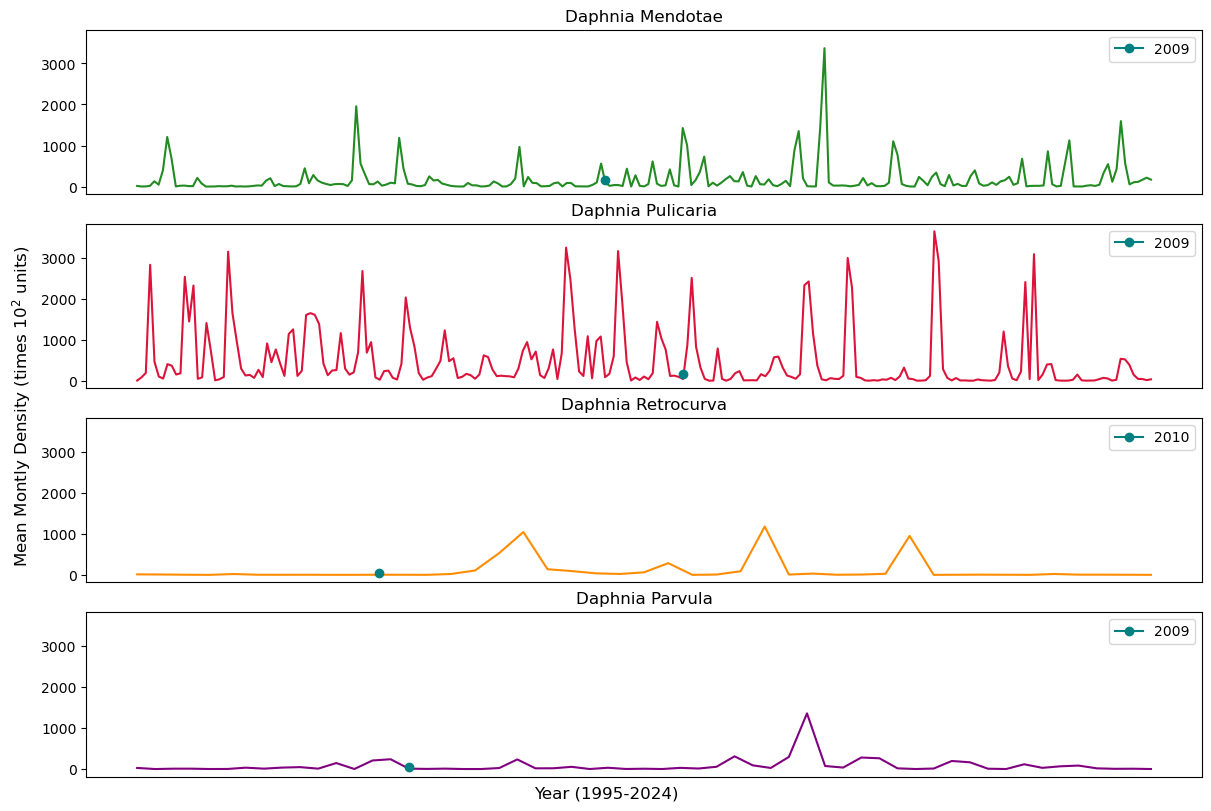

In [81]:
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(12, 8), sharey=True, layout="constrained")
fig.supylabel("Mean Montly Density (times $10^2$ units)", fontsize=12, fontweight='normal')
fig.supxlabel("Year (1995-2024)", fontsize=12, fontweight='normal')

axes[0].plot(daphnia_mendotae_data['year_month'], daphnia_mendotae_data['density']/100, color="forestgreen")
axes[0].set_title("Daphnia Mendotae")
axes[0].set_xticks([])
axes[0].plot("2009-01", 160, marker="o", color="teal", label='2009')
axes[0].legend()

axes[1].plot(daphnia_pulicaria_data['year_month'], daphnia_pulicaria_data['density']/100, color="crimson")
axes[1].set_title("Daphnia Pulicaria")
axes[1].set_xticks([])
axes[1].plot("2009-01", 160, marker="o", color="teal", label='2009')
axes[1].legend()

axes[2].plot(daphnia_retrocurva_data['year_month'], daphnia_retrocurva_data['density']/100, color="darkorange")
axes[2].set_title("Daphnia Retrocurva")
axes[2].set_xticks([])
axes[2].plot("2010-05", 45, marker="o", color="teal", label='2010')
axes[2].legend()

axes[3].plot(daphnia_parvula_data['year_month'], daphnia_parvula_data['density']/100, color="purple")
axes[3].set_title("Daphnia Parvula")
axes[3].set_xticks([])
axes[3].plot("2009-05", 60, marker="o", color="teal", label='2009')
axes[3].legend()

plt.show()

## Results Interpretation
* Daphnia Mendotae and Pulicaria appear most abundant, although the variation in the number of observations between Mendotae and Pulicaria versus Retrocurva and Parvula means we cannot make this conclusion with complete confidence
* **Daphnia Mendotae** appear to have experienced an increase in mean monthly density after 2009
* **Daphnia Pulicaria** showed no clear relationship between pre- and post-2009 population densities
* **Daphnia Retrocurva** seem to have experienced a modest mean population density increases (see 'Limitations')
* **Daphnia Parvula** appear to have experienced an even more modest mean population density increase at the very end of 2020, (see 'Limitations')

## Limitations
Daphnia Retrocurva and Parvula had substantially less recorded measurements for their population densities (i.e. Daphnia Retrocurva lacked observations after 2005-08 and before 2010-05), leading to some discrepancy when labeling the reference point for 2009 for Daphnia Retrocurva. The difference in numbers of measurements also makes it hard to definitively conclude that Daphnia Mendotae and Pulicaria were the most abundant, despite what is shown in the graph. 

## Next Step
The graph provides sufficient visual evidence to answer the posed research question. The next step I would take would be to look at what caused the variation in density of the daphnia populations. Particularly, I would be interesed in seeing if the peaks and valleys correlated with decreases and increases in the spiny water flea population, respectively.

## How has Mendota's average summer clarity changed yearly since 1995?

In [8]:
df1_ME = df1[df1["lakeid"] == "ME"].reset_index(drop=True)
df1_ME_cleaned = df1_ME.drop(['daynum', 'sta', 'secview', 'timeon', 'timeoff', 'windir', 'windspd', 'waveht', 'cloud', 'ice', 'airtemp'], axis = 1)
df1_ME_cleaned = df1_ME_cleaned.rename(columns={'year4':'year'})
df1_ME_cleaned = df1_ME_cleaned.dropna(subset=['secnview'])

In [9]:
target_months = ['06', '07', '08']
df1_ME_summers_1995_to_2024 = df1_ME_cleaned[df1_ME_cleaned["year"].between(1995, 2024) & df1_ME_cleaned["sampledate"].str.slice(5,7).isin(target_months)].copy()
annual_summer_avg = df1_ME_summers_1995_to_2024.groupby("year")["secnview"].mean()

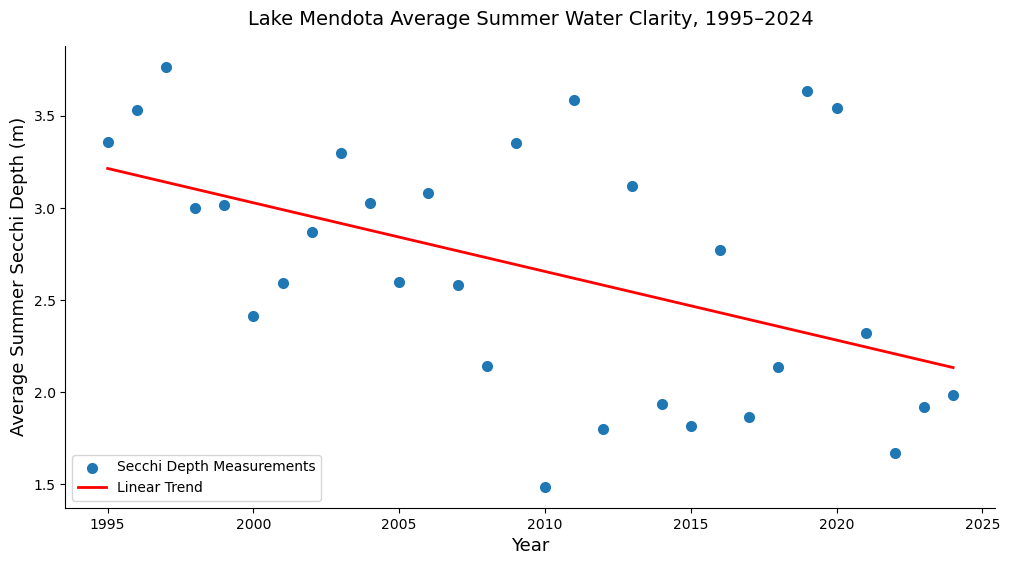

In [10]:
plt.figure(figsize=(12, 6))

plt.scatter(
    annual_summer_avg.index,
    annual_summer_avg.values,
    marker='o',
    linewidth=2,
    label='Secchi Depth Measurements'
)

plt.xlabel("Year", fontsize=13)
plt.ylabel("Average Summer Secchi Depth (m)", fontsize=13)
plt.title("Lake Mendota Average Summer Water Clarity, 1995–2024", fontsize=14, pad=15)
sns.despine()

x = annual_summer_avg.index
y = annual_summer_avg.values

x_with_intercept = sm.add_constant(x)
model = sm.OLS(y, x_with_intercept)
results = model.fit()
predictions = results.predict()

plt.plot(
    x,
    predictions,
    color="red",
    linewidth=2,
    label='Linear Trend'
)

plt.legend()
plt.show()

In [11]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.232
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     8.452
Date:                Sat, 21 Nov 2026   Prob (F-statistic):            0.00706
Time:                        12:55:24   Log-Likelihood:                -26.608
No. Observations:                  30   AIC:                             57.22
Df Residuals:                      28   BIC:                             60.02
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         77.6049     25.774      3.011      0.0

## Results Interpretation
* Moderate negative linear relationship between year and average summer secchi depth (coefficient of -0.0373 indicates an average loss of 0.0373 meters of clarity per year)
* Difference of -1.373 meters of clarity between oldest and most recent data point
* P-value of 0.007 proves results are statistically significant
* Passage of time (year) accounts for ~23.2% of the variation in water clarity, strongly suggesting there are other biological factors at play
* Indicates a long-term decrease in water clarity

## Did clarity become more variable from year to year after 2009, and not just lower on average?

In [12]:
clarity2009 = df1_ME_cleaned[df1_ME_cleaned['year']==2009]['secnview']
clarity2010 = df1_ME_cleaned[df1_ME_cleaned['year']==2010]['secnview']
clarity2011 = df1_ME_cleaned[df1_ME_cleaned['year']==2011]['secnview']
clarity2012 = df1_ME_cleaned[df1_ME_cleaned['year']==2012]['secnview']
clarity2013 = df1_ME_cleaned[df1_ME_cleaned['year']==2013]['secnview']
clarity2014 = df1_ME_cleaned[df1_ME_cleaned['year']==2014]['secnview']
clarity2015 = df1_ME_cleaned[df1_ME_cleaned['year']==2015]['secnview']
clarity2016 = df1_ME_cleaned[df1_ME_cleaned['year']==2016]['secnview']
clarity2017 = df1_ME_cleaned[df1_ME_cleaned['year']==2017]['secnview']
clarity2018 = df1_ME_cleaned[df1_ME_cleaned['year']==2018]['secnview']
clarity2019 = df1_ME_cleaned[df1_ME_cleaned['year']==2019]['secnview']
clarity2020 = df1_ME_cleaned[df1_ME_cleaned['year']==2020]['secnview']
clarity2021 = df1_ME_cleaned[df1_ME_cleaned['year']==2021]['secnview']
clarity2022 = df1_ME_cleaned[df1_ME_cleaned['year']==2022]['secnview']
clarity2023 = df1_ME_cleaned[df1_ME_cleaned['year']==2023]['secnview']
clarity2024 = df1_ME_cleaned[df1_ME_cleaned['year']==2024]['secnview']

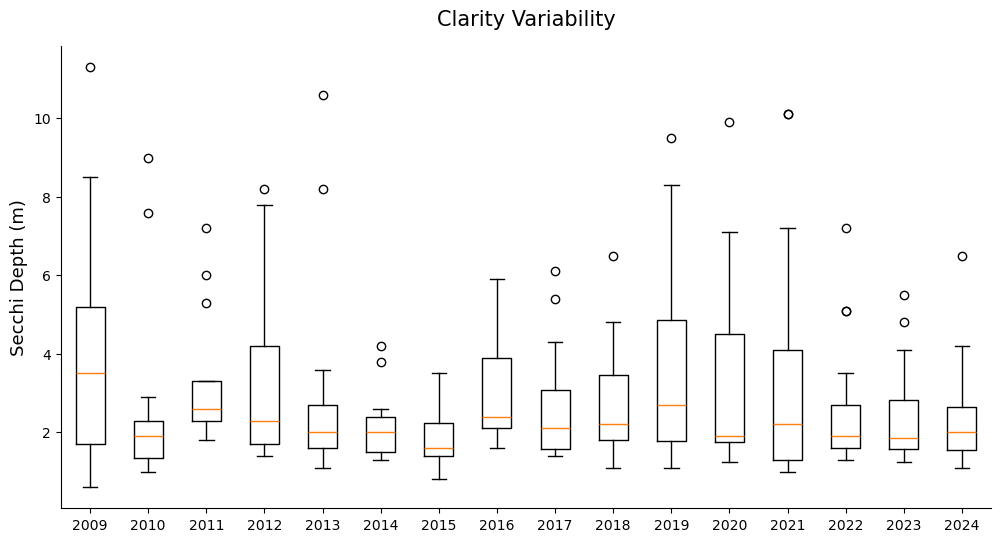

In [13]:
plt.figure(figsize=(12, 6))
plt.boxplot([clarity2009, clarity2010, clarity2011, clarity2012, clarity2013, clarity2014, clarity2015, clarity2016, clarity2017, clarity2018,
           clarity2019, clarity2020, clarity2021, clarity2022, clarity2023, clarity2024], tick_labels=['2009', '2010', '2011', '2012', '2013', '2014', '2015',
                                                                                                 '2016', '2017', '2018', '2019', '2020', '2021', '2022',
                                                                                                 '2023', '2024']);
plt.title('Clarity Variability', fontsize=15, pad=15)
plt.ylabel('Secchi Depth (m)', fontsize=13)
sns.despine()

## Results Interpretation
* Before 2015, secchi depth measurements were clustered more tightly around the mean for each year
* Increased variability starting in 2015 aligns with decrease in spiny water flea pop. densities, although this does not prove causation

# Key Findings
* The spiny water flea first arrived in Lake Mendota in 2009
* Before 2015, the population of spiny water fleas experienced in increase in its mean annual population density of 51.2 organisms/m² per year. Beginning in 2015 and continuing through 2024, the mean annual population density decreased by an average of ~6.57 organisms/m² per year.
* There does not appear to be a significant overarching trend in measures of daphnia population from 1995-2009, although each subspecies experienced its own variation and sub-trends
* There was a long-term decrease in the average summer water clarity of Lake Mendota from 1995-2024
* Water clarity variability increased beginning in 2015, aligning with a decrease in the spiny water flea population density

# Next Steps
This analysis could serve as the foundation for a deeper investigation into any one of the research areas (water clarity, zooplankton populations) it touches upon. For example, as stated previously, it could be advantageous to look into how well-explained the shifts in daphnia populations are by changes in the spiny water flea population. This would provide another layer of information that could be combined with the matrix of line charts used to chart the mean monthly population density for the four subspecies of daphnia.